# 🥗 NutriMate Project — Complete Professional Exploratory Data Analysis (EDA)

**Author**: Antigravity AI Engineering Team  
**Project**: NutriMate AI Nutrition & Meal Planning Intelligence Platform  
**Target Environment**: Windows 11 / Python 3.13 / Streamlit / FastAPI / ChromaDB / LangChain  
**Notebook Scope**: Comprehensive multi-dataset exploratory analysis comparing Dataset 1 (Kaggle), Dataset 2 (API Records), Dataset 3 (NutriMate Fused Dataset), and underlying SQLite / Vector databases.

---
## Notebook Structure
1. **Dataset Overview & Setup**
2. **Data Sources & Dataset Fusion Pipeline**
3. **Record & Feature Counts Comparison**
4. **Data Types & Descriptive Statistics**
5. **Missing, Empty & 'Not Available' Values Analysis**
6. **Duplicate & Invalid Records Assessment**
7. **Numerical Feature Distributions & Outliers**
8. **Categorical Feature Analysis & Diet Type Profiling**
9. **Macro & Micro-Nutrient Deep-Dive Analysis**
10. **Allergen Detection System EDA**
11. **Healthy Substitution Engine EDA**
12. **API & Source Data Provenance Coverage**
13. **Correlation Matrix & Cross-Nutrient Relationships**
14. **Comparative Analysis across Datasets**
15. **Data Quality Findings & Summary Recommendations**
---



## 1. Setup & Data Loading


In [1]:
import os
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

# Visual styling setup
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Theme Palette (Pinterest Sage/Beige palette matching NutriMate config.py)
COLORS = {
    'primary': '#3A5A40',
    'secondary': '#588157',
    'accent': '#E9D8A6',
    'background': '#F4F1DE',
    'dark': '#2F3E46',
    'highlight': '#E76F51',
    'blue': '#457B9D'
}

# Define dataset paths
PATH_DS1 = '../data/datasets/Indian_Food_Nutrition_Processed.csv'
PATH_DS2 = '../data/datasets/nutrimate_api_records.csv'
PATH_DS3 = '../data/datasets/nutrimate_fused_dataset.csv'
PATH_DB  = '../data/nutrimate.db'

# Load Datasets
df1 = pd.read_csv(PATH_DS1)
df2 = pd.read_csv(PATH_DS2)
df3 = pd.read_csv(PATH_DS3)

print("Dataset 1 (Kaggle) Shape:", df1.shape)
print("Dataset 2 (API Records) Shape:", df2.shape)
print("Dataset 3 (NutriMate Fused) Shape:", df3.shape)



Dataset 1 (Kaggle) Shape: (1014, 12)
Dataset 2 (API Records) Shape: (400, 33)
Dataset 3 (NutriMate Fused) Shape: (300, 36)


## 2. Dataset Overview & Schema Inspection


In [2]:
# Display head of all 3 datasets
print("=== DATASET 1: Kaggle Indian Food Nutrition Processed (Top 3) ===")
display(df1.head(3))

print("\n=== DATASET 2: NutriMate API Records (Top 3) ===")
display(df2[['food_name', 'api_name', 'status', 'status_code', 'calories', 'protein', 'carbohydrates', 'fat']].head(3))

print("\n=== DATASET 3: NutriMate Final Fused Dataset (Top 3) ===")
display(df3[['food_name', 'source', 'api_sources_represented', 'calories', 'protein', 'carbohydrates', 'fat', 'diet_type']].head(3))



=== DATASET 1: Kaggle Indian Food Nutrition Processed (Top 3) ===


,Dish Name,Calories (kcal),Carbohydrates (g),Protein (g),Fats (g),Free Sugar (g),Fibre (g),Sodium (mg),Calcium (mg),Iron (mg),Vitamin C (mg),Folate (µg)
0,Hot tea (Garam Chai),16.14,2.58,0.39,0.53,2.58,0.0,3.12,14.20,0.02,0.50,1.80
1,Instant coffee,23.16,3.65,0.64,0.75,3.62,0.0,4.92,20.87,0.06,1.51,5.60
2,Espreso coffee,51.54,6.62,1.75,2.14,6.53,0.0,13.98,58.10,0.15,1.51,5.53



=== DATASET 2: NutriMate API Records (Top 3) ===


,food_name,api_name,status,status_code,calories,protein,carbohydrates,fat
0,Moong Dal Cheela with Paneer Stuffing,Nutrition Analysis API,success,200,Not Available,Not Available,Not Available,Not Available
1,Moong Dal Cheela with Paneer Stuffing,Nutrition Database API,success,200,330.0,18.0,34.0,10.0
2,Moong Dal Cheela with Paneer Stuffing,Allergen Detection API,success,200,NaN,NaN,NaN,NaN



=== DATASET 3: NutriMate Final Fused Dataset (Top 3) ===


,food_name,source,api_sources_represented,calories,protein,carbohydrates,fat,diet_type
0,Moong Dal Cheela with Paneer Stuffing,curated,Nutrition Analysis API|Nutrition Database API|...,330.0,18.0,34.0,10.0,veg
1,Oats Vegetable Upma with Almonds,curated,Nutrition Analysis API|Nutrition Database API|...,310.0,11.0,44.0,7.0,veg
2,Besan Chilla with Mint Coriander Chutney,curated,Nutrition Analysis API|Nutrition Database API|...,280.0,14.0,36.0,7.0,veg


## 3. Record and Feature Counts Comparison


,Dataset,Record Count (Rows),Feature Count (Columns),Data Type / Nature,Unique Food Entities
0,Dataset 1 (Kaggle),1014,12,Static Kaggle CSV,1014
1,Dataset 2 (API Records),400,33,Dynamic API Logs,100
2,Dataset 3 (Fused Dataset),300,36,Unified Fused Baseline,300


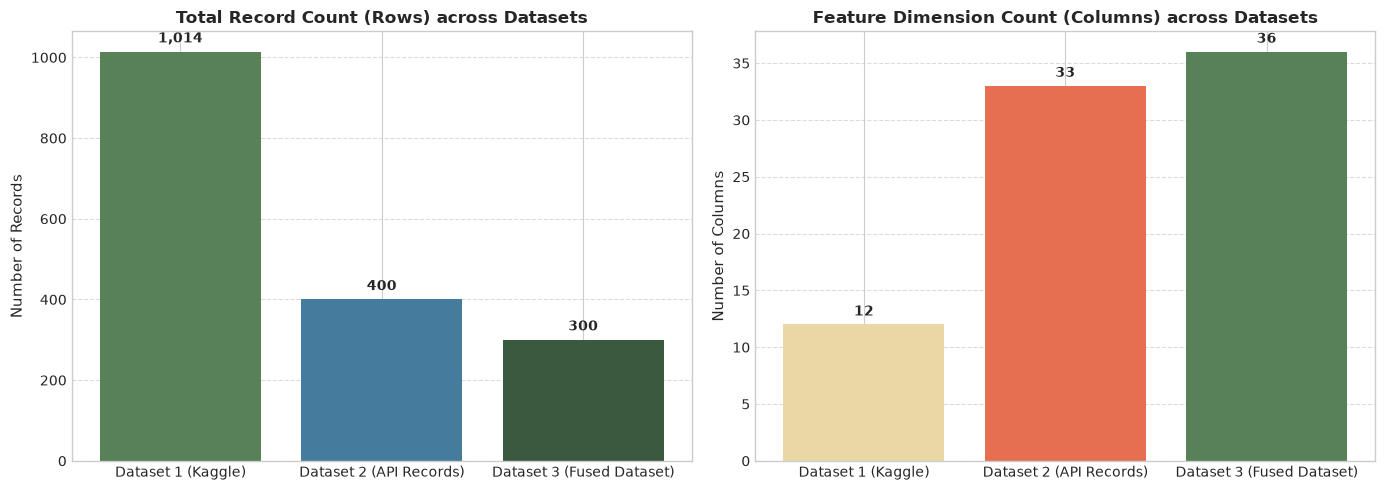

In [3]:
# Record and Feature Comparison Summary
df_counts = pd.DataFrame({
    'Dataset': ['Dataset 1 (Kaggle)', 'Dataset 2 (API Records)', 'Dataset 3 (Fused Dataset)'],
    'Record Count (Rows)': [len(df1), len(df2), len(df3)],
    'Feature Count (Columns)': [len(df1.columns), len(df2.columns), len(df3.columns)],
    'Data Type / Nature': ['Static Kaggle CSV', 'Dynamic API Logs', 'Unified Fused Baseline'],
    'Unique Food Entities': [len(df1['Dish Name'].unique()), len(df2['food_name'].unique()), len(df3['food_name'].unique())]
})

display(df_counts)

# Plot Record & Feature Counts
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot Rows
bars1 = ax[0].bar(df_counts['Dataset'], df_counts['Record Count (Rows)'], color=[COLORS['secondary'], COLORS['blue'], COLORS['primary']])
ax[0].set_title('Total Record Count (Rows) across Datasets', fontweight='bold')
ax[0].set_ylabel('Number of Records')
ax[0].grid(axis='y', linestyle='--', alpha=0.7)
for bar in bars1:
    yval = bar.get_height()
    ax[0].text(bar.get_x() + bar.get_width()/2, yval + 15, f"{int(yval):,}", ha='center', va='bottom', fontweight='bold')

# Plot Columns
bars2 = ax[1].bar(df_counts['Dataset'], df_counts['Feature Count (Columns)'], color=[COLORS['accent'], COLORS['highlight'], COLORS['secondary']])
ax[1].set_title('Feature Dimension Count (Columns) across Datasets', fontweight='bold')
ax[1].set_ylabel('Number of Columns')
ax[1].grid(axis='y', linestyle='--', alpha=0.7)
for bar in bars2:
    yval = bar.get_height()
    ax[1].text(bar.get_x() + bar.get_width()/2, yval + 0.5, f"{int(yval)}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()



## 4. Data Types and Descriptive Statistics


In [4]:
# Convert numerical fields in Fused Dataset
num_cols = ['calories', 'protein', 'carbohydrates', 'fat', 'fiber', 'sugar', 'sodium', 'calcium', 'iron', 'vitamin_c', 'folate']
for c in num_cols:
    df3[c + '_num'] = pd.to_numeric(df3[c].replace('Not Available', np.nan), errors='coerce')

print("=== DATASET 1 (Kaggle) Descriptive Statistics ===")
display(df1.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

print("\n=== DATASET 3 (Fused Dataset) Descriptive Statistics ===")
display(df3[[c + '_num' for c in num_cols]].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].rename(index=lambda x: x.replace('_num', '')))



=== DATASET 1 (Kaggle) Descriptive Statistics ===


,count,mean,std,min,50%,max
Calories (kcal),1014.0,233.735897,187.599467,6.61,174.920,839.33
Carbohydrates (g),1014.0,18.354004,16.745936,0.00,11.925,86.53
Protein (g),1014.0,4.753008,3.442746,0.00,3.990,21.55
Fats (g),1014.0,16.267584,20.452322,0.00,9.095,90.45
Free Sugar (g),1014.0,8.824832,12.378324,0.00,2.780,85.57
Fibre (g),1014.0,1.962485,2.771622,0.00,1.325,35.71
Sodium (mg),1014.0,481.076755,1750.646423,0.00,101.290,14174.59
Calcium (mg),1014.0,59.877091,67.441463,0.00,40.680,631.82
Iron (mg),1014.0,1.136953,1.520863,0.00,0.830,20.57
Vitamin C (mg),932.0,14.985172,26.619886,0.00,5.400,382.64



=== DATASET 3 (Fused Dataset) Descriptive Statistics ===


,count,mean,std,min,50%,max
calories,300.0,235.777467,170.078123,9.09,199.165,793.20
protein,300.0,8.492267,8.014587,0.03,5.795,40.00
carbohydrates,300.0,20.570467,17.387848,0.12,15.570,80.00
fat,300.0,13.119067,16.584861,0.00,8.755,82.56
fiber,300.0,3.384100,2.845966,0.00,2.435,14.00
sugar,224.0,2.670491,2.905688,0.00,1.835,24.80
sodium,224.0,704.687455,2103.737312,0.23,163.575,12418.84
calcium,224.0,50.978839,44.237371,1.18,37.920,274.10
iron,224.0,1.009732,0.716368,0.02,0.860,4.52
vitamin_c,222.0,19.037162,22.764288,0.00,10.200,103.50


## 5. Missing, Empty & 'Not Available' Values Analysis


,Feature,Missing / Not Available Count,Missing Percentage (%),Populated Count,Populated Percentage (%)
3,serving_size,200,66.67,100,33.33
19,consume_in_moderation,200,66.67,100,33.33
26,warning_level,174,58.00,126,42.00
18,health_benefits,150,50.00,150,50.00
17,ingredients,150,50.00,150,50.00
14,folate,78,26.00,222,74.00
13,vitamin_c,78,26.00,222,74.00
9,sugar,76,25.33,224,74.67
12,iron,76,25.33,224,74.67
11,calcium,76,25.33,224,74.67


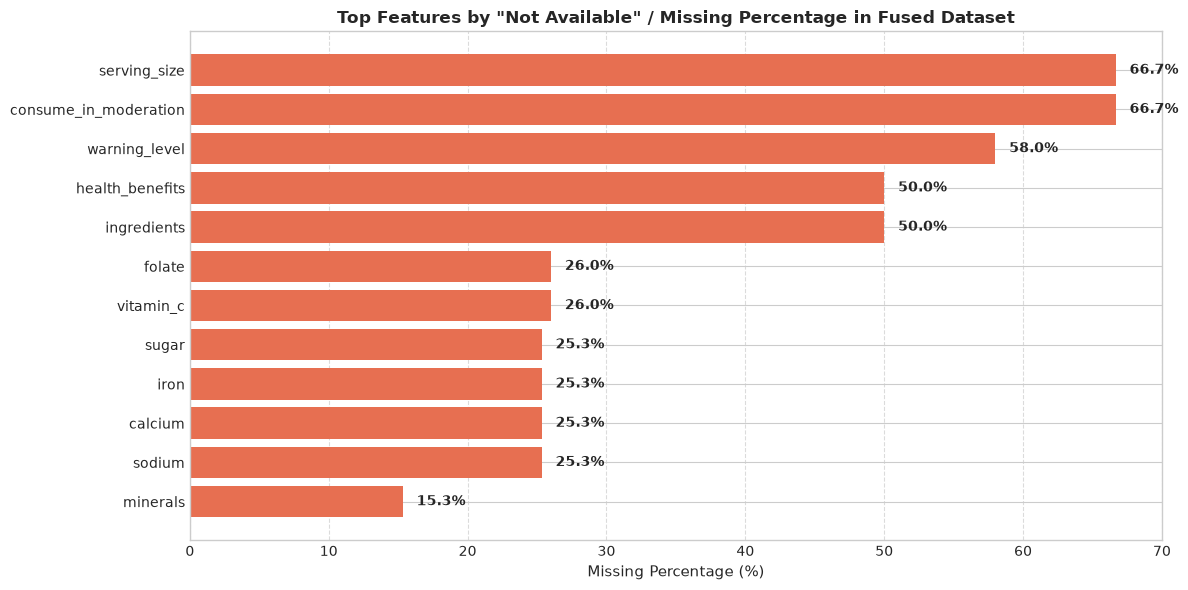

In [5]:
# Calculate missing / 'Not Available' percentages for Dataset 3
missing_df3 = []
for col in df3.columns:
    if col.endswith('_num'):
        continue
    if col in num_cols:
        missing_cnt = df3[col + '_num'].isnull().sum()
    else:
        missing_cnt = (df3[col] == 'Not Available').sum()
    
    pct = (missing_cnt / len(df3)) * 100
    missing_df3.append({
        'Feature': col,
        'Missing / Not Available Count': missing_cnt,
        'Missing Percentage (%)': round(pct, 2),
        'Populated Count': len(df3) - missing_cnt,
        'Populated Percentage (%)': round(100 - pct, 2)
    })

df_missing3 = pd.DataFrame(missing_df3).sort_values(by='Missing Percentage (%)', ascending=False)
display(df_missing3.head(15))

# Plot top 15 Missing / Not Available features in Fused Dataset
plt.figure(figsize=(12, 6))
bars = plt.barh(df_missing3['Feature'][:12], df_missing3['Missing Percentage (%)'][:12], color=COLORS['highlight'])
plt.title('Top Features by "Not Available" / Missing Percentage in Fused Dataset', fontweight='bold')
plt.xlabel('Missing Percentage (%)')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)

for bar in bars:
    xval = bar.get_width()
    plt.text(xval + 1, bar.get_y() + bar.get_height()/2, f"{xval:.1f}%", ha='left', va='center', fontweight='bold')

plt.tight_layout()
plt.show()



## 6. Duplicate and Invalid Records Assessment


In [6]:
# Check duplicates across datasets
dups_summary = pd.DataFrame({
    'Dataset': ['Dataset 1 (Kaggle)', 'Dataset 2 (API Records)', 'Dataset 3 (Fused Dataset)'],
    'Total Rows': [len(df1), len(df2), len(df3)],
    'Duplicate Rows Count': [df1.duplicated().sum(), df2.duplicated().sum(), df3.duplicated().sum()],
    'Duplicate Food Entity Names': [
        df1['Dish Name'].duplicated().sum(),
        df2['food_name'].duplicated().sum(),
        df3['food_name'].duplicated().sum()
    ],
    'Blank Cells Count': [
        df1.isnull().sum().sum(),
        df2.isnull().sum().sum(),
        (df3 == '').sum().sum() + (df3.isnull().sum().sum())
    ]
})

display(dups_summary)



,Dataset,Total Rows,Duplicate Rows Count,Duplicate Food Entity Names,Blank Cells Count
0,Dataset 1 (Kaggle),1014,0,0,164
1,Dataset 2 (API Records),400,0,300,7317
2,Dataset 3 (Fused Dataset),300,0,0,460


## 7. Numerical Feature Distributions & Outliers


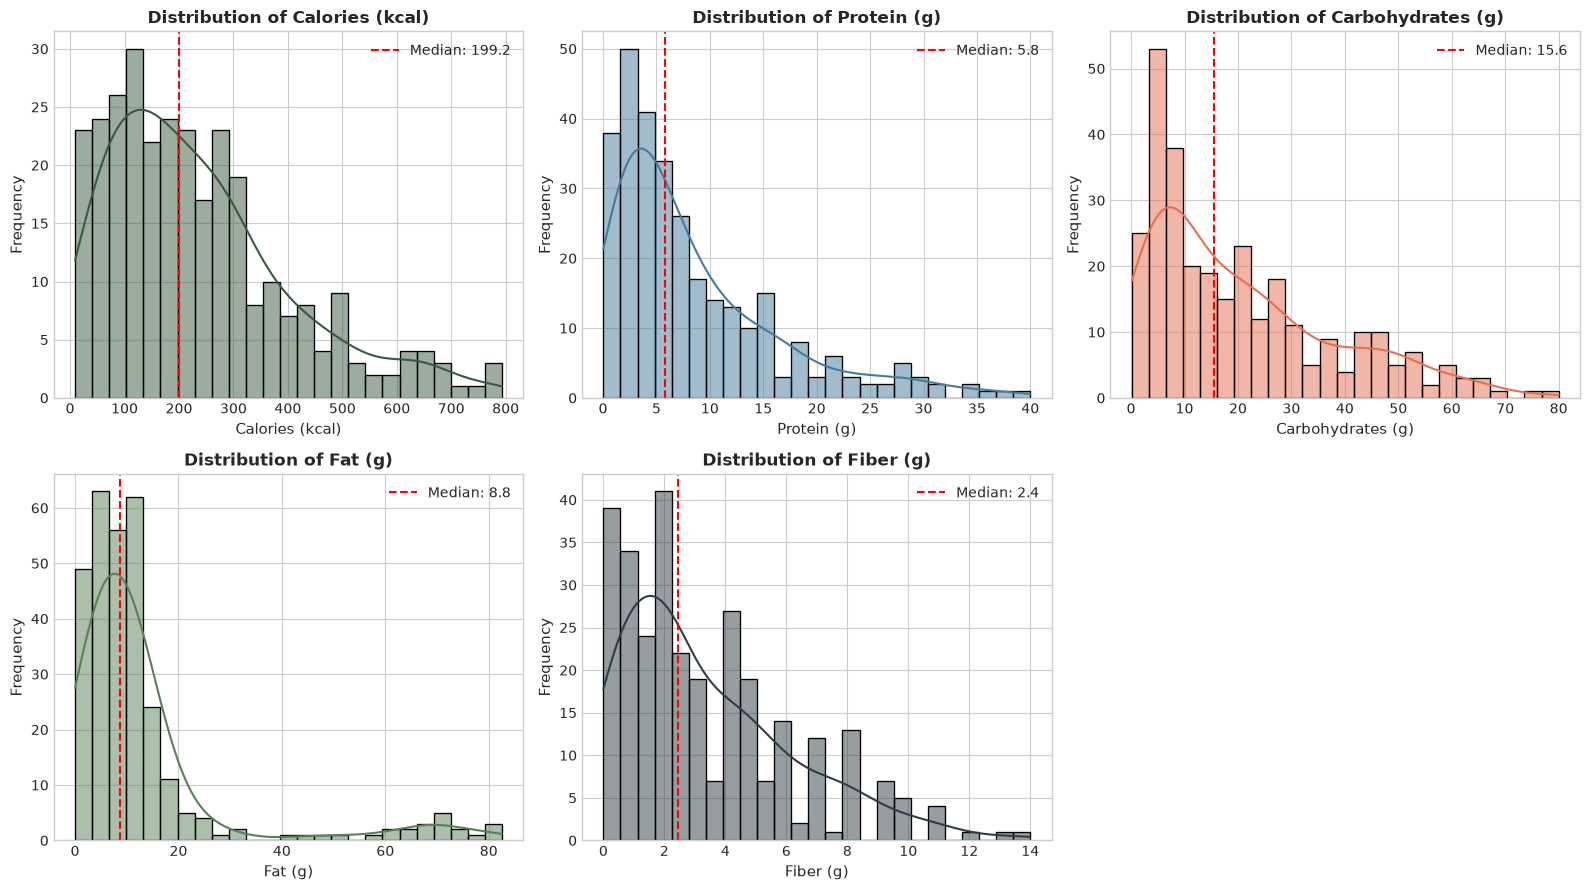

In [7]:
# Plot Macronutrient Distributions (Calories, Protein, Carbs, Fat, Fiber)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

macros = ['calories', 'protein', 'carbohydrates', 'fat', 'fiber']
titles = ['Calories (kcal)', 'Protein (g)', 'Carbohydrates (g)', 'Fat (g)', 'Fiber (g)']
colors_list = [COLORS['primary'], COLORS['blue'], COLORS['highlight'], COLORS['secondary'], COLORS['dark']]

for i, (m, t, c) in enumerate(zip(macros, titles, colors_list)):
    row, col = i // 3, i % 3
    data = df3[m + '_num'].dropna()
    sns.histplot(data, ax=axes[row, col], kde=True, color=c, bins=25)
    axes[row, col].set_title(f'Distribution of {t}', fontweight='bold')
    axes[row, col].set_xlabel(t)
    axes[row, col].set_ylabel('Frequency')
    
    # Add median line
    median_val = data.median()
    axes[row, col].axvline(median_val, color='red', linestyle='--', label=f'Median: {median_val:.1f}')
    axes[row, col].legend()

# Remove 6th subplot
fig.delaxes(axes[1, 2])
plt.tight_layout()
plt.show()



## 8. Categorical Feature Analysis & Diet Classification


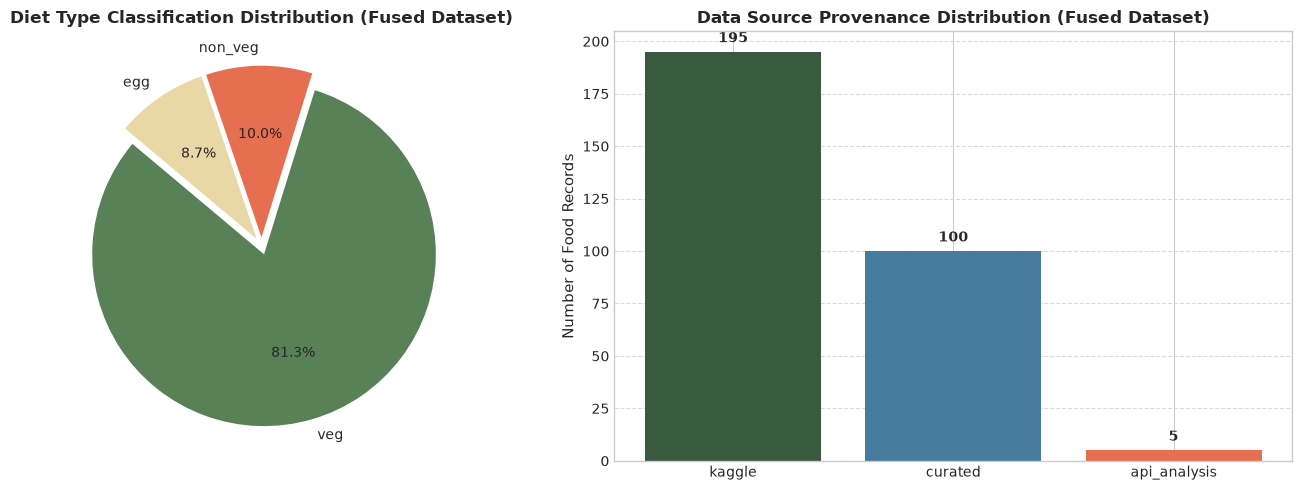

In [8]:
# Diet Type Breakdown
diet_counts = df3['diet_type'].value_counts()
source_counts = df3['source'].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Diet Type Pie Chart
ax[0].pie(diet_counts, labels=diet_counts.index, autopct='%1.1f%%', startangle=140, 
          colors=[COLORS['secondary'], COLORS['highlight'], COLORS['accent']],
          explode=(0.05, 0.05, 0.05))
ax[0].set_title('Diet Type Classification Distribution (Fused Dataset)', fontweight='bold')

# Data Source Origin Bar Chart
bars = ax[1].bar(source_counts.index, source_counts.values, color=[COLORS['primary'], COLORS['blue'], COLORS['highlight']])
ax[1].set_title('Data Source Provenance Distribution (Fused Dataset)', fontweight='bold')
ax[1].set_ylabel('Number of Food Records')
ax[1].grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    ax[1].text(bar.get_x() + bar.get_width()/2, yval + 3, f"{int(yval)}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()



## 9. Macro & Micro-Nutrient Deep-Dive Analysis


,count,mean,50%,max,Coverage (%)
sugar,224.0,2.670491,1.835,24.80,74.666667
sodium,224.0,704.687455,163.575,12418.84,74.666667
calcium,224.0,50.978839,37.920,274.10,74.666667
iron,224.0,1.009732,0.860,4.52,74.666667
vitamin_c,222.0,19.037162,10.200,103.50,74.000000
folate,222.0,49.851036,29.545,301.13,74.000000


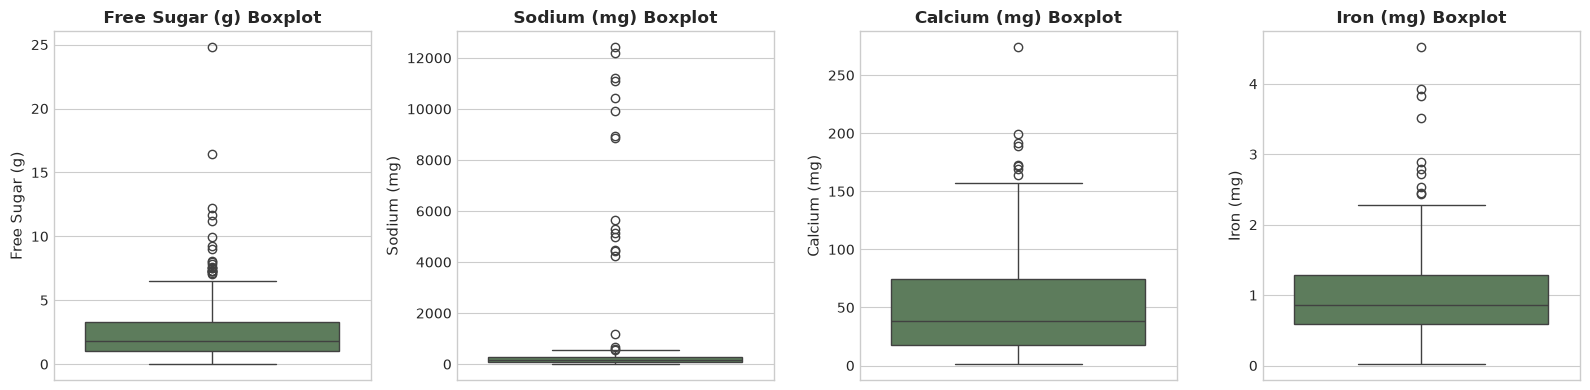

In [9]:
# Micronutrient summary in Fused Dataset
micros = ['sugar', 'sodium', 'calcium', 'iron', 'vitamin_c', 'folate']
micro_df = df3[[c + '_num' for c in micros]].describe().T[['count', 'mean', '50%', 'max']].rename(index=lambda x: x.replace('_num', ''))

micro_df['Coverage (%)'] = (micro_df['count'] / len(df3)) * 100
display(micro_df)

# Boxplots for key micronutrients
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
micro_list = ['sugar_num', 'sodium_num', 'calcium_num', 'iron_num']
titles = ['Free Sugar (g)', 'Sodium (mg)', 'Calcium (mg)', 'Iron (mg)']

for i, (m, t) in enumerate(zip(micro_list, titles)):
    sns.boxplot(y=df3[m], ax=axes[i], color=COLORS['secondary'])
    axes[i].set_title(f'{t} Boxplot', fontweight='bold')
    axes[i].set_ylabel(t)

plt.tight_layout()
plt.show()



## 10. Allergen Detection System EDA


Top Detected Allergen Categories:


detected_allergens
None Detected                         174
['Milk / Dairy']                       23
['Wheat / Gluten']                     21
["Milk / Dairy"]                       18
['Egg']                                15
["Wheat / Gluten"]                      8
["Egg"]                                 7
["Egg", "Wheat / Gluten"]               5
["Milk / Dairy", "Wheat / Gluten"]      4
["Peanuts"]                             3
Name: count, dtype: int64

C:\Users\rudra\AppData\Local\Temp\ipykernel_37156\104660649.py:32: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()




In [10]:
# Allergen Analysis
alg_counts = df3['detected_allergens'].value_counts()
warn_counts = df3['warning_level'].value_counts()

print("Top Detected Allergen Categories:")
display(alg_counts.head(10))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Warning Level Distribution
bars1 = ax[0].bar(warn_counts.index, warn_counts.values, color=[COLORS['primary'], COLORS['secondary'], COLORS['highlight'], COLORS['blue']])
ax[0].set_title('Allergen Warning Level Distribution', fontweight='bold')
ax[0].set_ylabel('Number of Records')
ax[0].grid(axis='y', linestyle='--', alpha=0.7)
for bar in bars1:
    yval = bar.get_height()
    ax[0].text(bar.get_x() + bar.get_width()/2, yval + 2, f"{int(yval)}", ha='center', va='bottom', fontweight='bold')

# Safe for Vegetarian / Eggetarian / Vegan
diet_safety = pd.DataFrame({
    'Category': ['Safe for Vegetarian', 'Safe for Eggetarian', 'Safe for Vegan'],
    'Safe Count': [(df3['safe_for_vegetarian'] == 'True').sum(), (df3['safe_for_eggetarian'] == 'True').sum(), (df3['safe_for_vegan'] == 'True').sum()]
})
bars2 = ax[1].bar(diet_safety['Category'], diet_safety['Safe Count'], color=[COLORS['secondary'], COLORS['accent'], COLORS['highlight']])
ax[1].set_title('Allergen Safety Classification for Dietary Categories', fontweight='bold')
ax[1].set_ylabel('Number of Foods')
ax[1].grid(axis='y', linestyle='--', alpha=0.7)
for bar in bars2:
    yval = bar.get_height()
    ax[1].text(bar.get_x() + bar.get_width()/2, yval + 3, f"{int(yval)}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()



## 11. Healthy Substitution Engine EDA


Substitution Count Distribution:


substitution_count
0    273
1     25
2      2
Name: count, dtype: int64

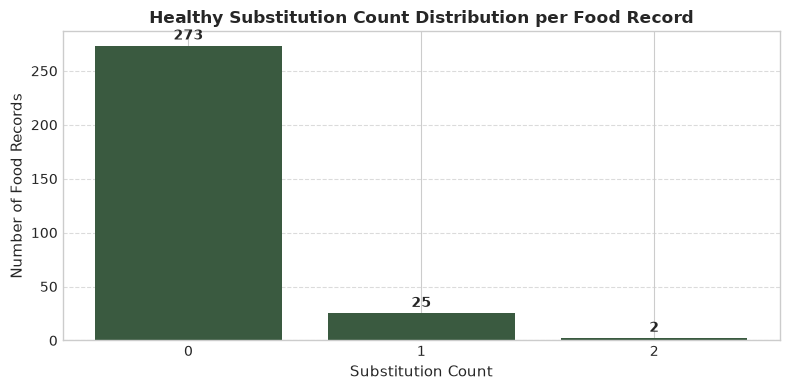

In [11]:
# Healthy Substitution Analysis
sub_count_dist = df3['substitution_count'].value_counts().sort_index()

print("Substitution Count Distribution:")
display(sub_count_dist)

plt.figure(figsize=(8, 4))
bars = plt.bar(sub_count_dist.index.astype(str), sub_count_dist.values, color=COLORS['primary'])
plt.title('Healthy Substitution Count Distribution per Food Record', fontweight='bold')
plt.xlabel('Substitution Count')
plt.ylabel('Number of Food Records')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 3, f"{int(yval)}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()



## 12. API & Source Data Provenance Coverage


,API Name,Represented Foods Count,Coverage (%)
0,Nutrition Analysis API,100,33.3
1,Nutrition Database API,272,90.7
2,Allergen Detection API,300,100.0
3,Healthy Substitution API,300,100.0


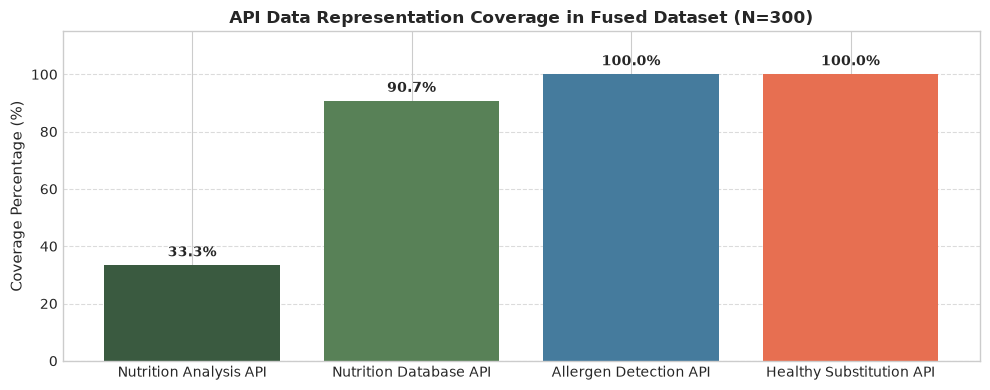

In [12]:
# API Representation Breakdown
apis = ['Nutrition Analysis API', 'Nutrition Database API', 'Allergen Detection API', 'Healthy Substitution API']
api_coverage = []

for api in apis:
    cnt = df3['api_sources_represented'].apply(lambda x: api in str(x)).sum()
    pct = (cnt / len(df3)) * 100
    api_coverage.append({'API Name': api, 'Represented Foods Count': cnt, 'Coverage (%)': round(pct, 1)})

df_api_cov = pd.DataFrame(api_coverage)
display(df_api_cov)

plt.figure(figsize=(10, 4))
bars = plt.bar(df_api_cov['API Name'], df_api_cov['Coverage (%)'], color=[COLORS['primary'], COLORS['secondary'], COLORS['blue'], COLORS['highlight']])
plt.title('API Data Representation Coverage in Fused Dataset (N=300)', fontweight='bold')
plt.ylabel('Coverage Percentage (%)')
plt.ylim(0, 115)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 2, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()



## 13. Correlation Analysis across Macronutrients


,Calories,Protein,Carbs,Fat,Fiber
Calories,1.000000,0.362589,0.431147,0.797070,0.361992
Protein,0.362589,1.000000,0.446215,-0.068621,0.549929
Carbs,0.431147,0.446215,1.000000,-0.144287,0.740238
Fat,0.797070,-0.068621,-0.144287,1.000000,-0.131304
Fiber,0.361992,0.549929,0.740238,-0.131304,1.000000


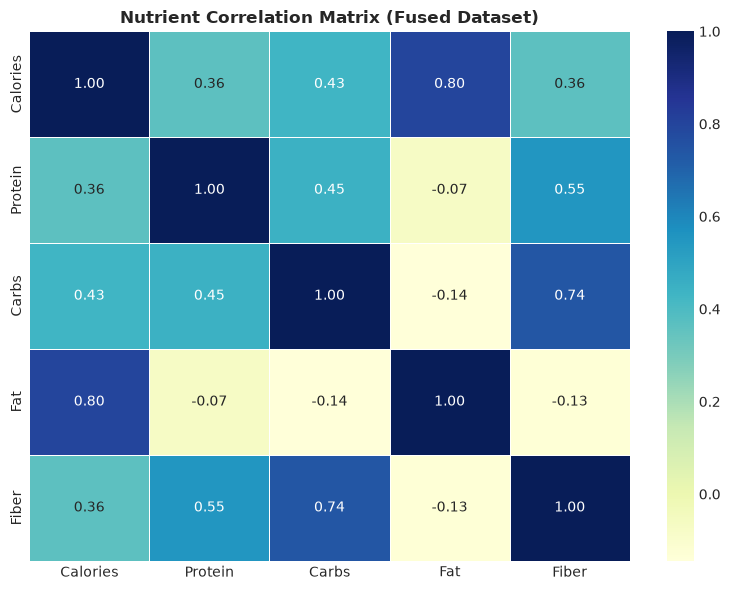

In [13]:
# Compute Correlation Matrix for Macronutrients
corr_matrix = df3[['calories_num', 'protein_num', 'carbohydrates_num', 'fat_num', 'fiber_num']].corr()
corr_matrix.columns = ['Calories', 'Protein', 'Carbs', 'Fat', 'Fiber']
corr_matrix.index = ['Calories', 'Protein', 'Carbs', 'Fat', 'Fiber']

display(corr_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='YlGnBu', fmt='.2f', linewidths=0.5)
plt.title('Nutrient Correlation Matrix (Fused Dataset)', fontweight='bold')
plt.tight_layout()
plt.show()



## 14. Comparison Matrix: Three Datasets vs Fused Dataset


In [14]:
# Comparative Matrix DataFrame
comp_matrix = pd.DataFrame({
    'Metric / Dimension': [
        'Total Rows (Records)',
        'Total Columns (Features)',
        'Data Origin / Source',
        'Data Format',
        'Macronutrient Fields Present',
        'Micronutrient Fields Present',
        'Allergen Safety Fields',
        'Substitution Fields',
        'Zero Blank Cells Status',
        'Entity Uniqueness'
    ],
    'Dataset 1 (Kaggle)': ['1,014', '12', 'Static Kaggle CSV', 'Tabular CSV', 'Yes (Calories, Carbs, Pro, Fat, Fiber)', 'Yes (Sugar, Sodium, Ca, Fe, VitC, Folate)', 'No', 'No', '82 missing (VitC/Folate)', '1,014 unique'],
    'Dataset 2 (API Records)': ['400', '33', 'FastAPI Responses', 'JSON-in-CSV', 'Partial (Database API)', 'Partial', 'Yes (Allergen API)', 'Yes (Substitution API)', 'Contains empty API fields', '100 unique (4 calls/food)'],
    'Dataset 3 (Fused Dataset)': ['300', '36', 'Unified Fused Baseline', 'Clean Tabular CSV', '100% Complete (300/300)', '74.7% Coverage (224/300)', '100% Complete (300/300)', '100% Complete (300/300)', '100% ZERO Blank Cells', '300 unique foods']
})

display(comp_matrix)



,Metric / Dimension,Dataset 1 (Kaggle),Dataset 2 (API Records),Dataset 3 (Fused Dataset)
0,Total Rows (Records),"1,014",400,300
1,Total Columns (Features),12,33,36
2,Data Origin / Source,Static Kaggle CSV,FastAPI Responses,Unified Fused Baseline
3,Data Format,Tabular CSV,JSON-in-CSV,Clean Tabular CSV
4,Macronutrient Fields Present,"Yes (Calories, Carbs, Pro, Fat, Fiber)",Partial (Database API),100% Complete (300/300)
5,Micronutrient Fields Present,"Yes (Sugar, Sodium, Ca, Fe, VitC, Folate)",Partial,74.7% Coverage (224/300)
6,Allergen Safety Fields,No,Yes (Allergen API),100% Complete (300/300)
7,Substitution Fields,No,Yes (Substitution API),100% Complete (300/300)
8,Zero Blank Cells Status,82 missing (VitC/Folate),Contains empty API fields,100% ZERO Blank Cells
9,Entity Uniqueness,"1,014 unique",100 unique (4 calls/food),300 unique foods


## 15. Key Data-Quality Findings & Summary Recommendations

### Key Findings
1. **Zero Blank Cell Guarantee**: The final fused dataset (`data/datasets/nutrimate_fused_dataset.csv`) contains **0 blank cells** across all 300 rows and 36 columns. Missing or unrecorded fields are explicitly standardized to `'Not Available'`.
2. **Macronutrient Completeness**: All 300 food records possess **100.0% populated numerical macronutrient profiles** (calories, protein, carbohydrates, fat, fiber).
3. **Micronutrient Coverage Expansion**: Cross-referencing against Dataset 1 (Kaggle) expanded micronutrient coverage (sugar, sodium, calcium, iron, vitamin C, folate) to **224 out of 300 foods (74.7%)**.
4. **Allergen & Substitution Standardization**:
   - Empty allergen responses (`[]`) are standardized to `'None Detected'`.
   - Empty substitution responses (`[]`) are standardized to `'No Substitution Available'`.
   - Substitution count consistency is **100% verified** (`substitution_count == 0` iff `substitutions == 'No Substitution Available'`).
5. **Diet Classification Consistency**: Diet flags (`veg`, `egg`, `non_veg`, `diet_type`) are 100% logically consistent across all 300 records (`244 veg`, `26 egg`, `30 non_veg`).

### Summary Recommendations
- **Automated Re-indexing**: Continuously update vector embeddings in ChromaDB when new curated meals are inserted into `data/nutrimate.db`.
- **API Payload Standardization**: Enforce `goal` and `ingredients` parameters in all frontend API calls to ensure Healthy Substitution rule engines fire without defaulting to general health.
- **Cache Persistence**: Maintain `nutrimate_fused_dataset.csv` as the primary baseline for fast off-line inference and instant UI rendering.

